In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import shutil
import glob
import logging
import xml.etree.ElementTree as ET

from pathlib import Path
from io import StringIO
from typing import Dict, List, Optional, Union
from functools import reduce
import multiprocess as mp
from multiprocessing import cpu_count

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from tqdm.contrib.logging import logging_redirect_tqdm
import logging

import parmed
from openbabel import openbabel

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

from plip.structure.preparation import PDBComplex, logger as PLIP_LOGGER
from plip.exchange.report import StructureReport
from plip.basic import config as PLIP_CONFIG

PLIP_LOGGER.setLevel(logging.ERROR)
PLIP_LOGGER.propagate = False

In [2]:
cwdir = os.getcwd()
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
subdirs = ['biolip2_opt/',
           'pdbbind_opt_poly/',
           'pdbbind_opt_sm/']

def generate_PDBIDs():
    fcsv = os.path.join(dataset_dir, 'PDBIDs.csv')
    df_PDBIDs = pd.read_csv(fcsv)
    PDBIDs = (df_PDBIDs.T).to_numpy()
    PDBIDs = PDBIDs.tolist()
    PDBIDs = [[x for x in row if x is not None and not (isinstance(x, float) and math.isnan(x))]for row in PDBIDs]
    return PDBIDs

def generate_args():
    args = []
    for index, subdir in enumerate(subdirs):
        for PDBID in PDBIDs[index]:
            args.append((
                PDBID,
                subdir,
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.sdf'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_protein_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_complex.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/interaction.xml'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/HbondProteinFragment'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/HbondLigandFragment')
            ))
    return args

PDBIDs = generate_PDBIDs()
args = generate_args()

PDBIDs = generate_PDBIDs()
args = generate_args()

In [3]:
def extract_hbond(xmlpath):
    xmlobj = ET.parse(xmlpath)
    binding_sites = xmlobj.findall("./bindingsite")
    bs = [bs for bs in binding_sites if bs.findall("identifiers/longname")[0].text == "UNL"][0]
    hbonds = bs.findall("interactions/hydrogen_bonds/hydrogen_bond")
    infos = []
    for hbond in hbonds:
        info = {}
        for attr in hbond:
            if attr.tag == 'ligcoo' or attr.tag == 'protcoo':
                for s in ['x', 'y', 'z']:
                    info[f'{attr.tag}_{s}'] = attr.find(s).text
            else:
                info[attr.tag] = attr.text
        infos.append(info)
    return infos

def make_identifier(code, resnr, restype, sidechain, donoridx, acceptoridx):
    ifsc = "SC" if sidechain else "BB"
    return f'{code}_{resnr}_{restype}_{ifsc}_{donoridx}_{acceptoridx}'

def make_identifier_from_row(row):
    return make_identifier(row['full_PDBID'], row['resnr'], row['restype'], eval(row['sidechain']), row['donoridx'], row['acceptoridx'])

In [40]:
df = []
errs = []

for arg in tqdm(args):
    try:
        infos = extract_hbond(arg[6])
        for info in infos:
            info['PDBID'] = arg[0][:4]
            info['full_PDBID'] = arg[0]
            info['subdir'] = arg[1]
            df.append(info)
    except Exception as e:
        errs.append((arg[0], e))

print(len(errs))
df = pd.DataFrame(df)
cols = ['PDBID'] + ['full_PDBID'] + ['subdir'] + list(df.columns[:-3])
df = df[cols]
# # filter bad halogen-bonds: PLIP will identify N-H...F as halogenbonds but it is actually hydrogen bonds

# bads = ['Ng+', 'Nam', 'N3+']
# df = df.query('acceptortype not in @bads')
# # filter terminal residues
# df = df.query('not (sidechain == "False" & acceptortype == "O.co2")')

df.index = [make_identifier_from_row(row) for index, row in df.iterrows()]
fcsv = os.path.join(cwdir, 'hbonds.csv')
df.to_csv(fcsv)
df

100%|██████████| 18928/18928 [00:13<00:00, 1389.57it/s]


0


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,sidechain,...,donoridx,donortype,acceptoridx,acceptortype,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
1a8g_2Z4_A_100_26_ASP_SC_30_540,1a8g,1a8g_2Z4_A_100,biolip2_opt/,26,ASP,A,1,UNL,Z,True,...,30,N3,540,O.co2,-11.132,15.891,27.156,-13.071,18.518,26.135
1a8g_2Z4_A_100_28_GLY_BB_19_561,1a8g,1a8g_2Z4_A_100,biolip2_opt/,28,GLY,A,1,UNL,Z,False,...,19,Nam,561,O2,-8.671,17.529,26.081,-8.958,20.316,25.214
1a8g_2Z4_A_100_30_ASP_BB_572_2,1a8g,1a8g_2Z4_A_100,biolip2_opt/,30,ASP,A,1,UNL,Z,False,...,572,Nam,2,O2,-7.007,18.999,22.315,-9.176,20.874,21.009
1a8g_2Z4_A_100_49_GLY_BB_11_894,1a8g,1a8g_2Z4_A_100,biolip2_opt/,49,GLY,A,1,UNL,Z,False,...,11,Nam,894,O2,-6.760,17.067,23.253,-5.030,14.748,22.720
1a8g_2Z4_A_100_125_ASP_SC_29_2107,1a8g,1a8g_2Z4_A_100,biolip2_opt/,125,ASP,B,1,UNL,Z,True,...,29,O3,2107,O.co2,-10.775,18.588,27.483,-11.294,21.553,28.760
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_49_GLY_BB_11_880,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,49,GLY,A,1,UNL,Z,False,...,11,Nam,880,O2,-10.976,14.541,32.506,-10.125,11.955,32.662
9hvp_0E9_A_100_127_GLY_BB_24_2115,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,127,GLY,B,1,UNL,Z,False,...,24,Nam,2115,O2,-8.621,17.469,26.005,-8.360,21.000,24.866
9hvp_0E9_A_100_129_ASP_BB_2126_46,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,129,ASP,B,1,UNL,Z,False,...,2126,Nam,46,O2,-7.563,18.410,21.875,-8.915,20.714,21.020
9hvp_0E9_A_100_130_ASP_BB_2138_46,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,130,ASP,B,1,UNL,Z,False,...,2138,Nam,46,O2,-7.563,18.410,21.875,-10.001,19.580,18.943


In [5]:
hbond_dir = os.getcwd()
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
subdirs = ['biolip2_opt/',
            'pdbbind_opt_poly/',
            'pdbbind_opt_sm/']

df = pd.read_csv("hbonds.csv", index_col=0)

def interactions(df):
    interactions = []
    for index, row in tqdm(df.iterrows()):
        interactions.append((
            row['PDBID'], 
            row['full_PDBID'],
            row['subdir'],
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb"),
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/interaction.xml"),
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HbondProteinFragment"),
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HbondLigandFragment"), 
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"),
            row['donoridx'], 
            row['acceptoridx'], 
            row['protisdon'],
            index,
            row['restype'],
            row['sidechain']
        ))
    return interactions

hbonds = interactions(df)

85222it [00:03, 26203.10it/s]


# Fragment Protein

In [44]:
FRAG_SIDE_CHAIN = {
    'ASP': ['OD1', 'OD2', 'CG', 'CB', 'HB2', 'HB3'],
    'GLU': ['OE1', 'OE2', 'CD', 'CG', 'HG2', 'HG3'],
    'LYS': ['NZ', 'HZ1', 'HZ2', 'HZ3', 'CE', 'HE2', 'HE3'],
    'ARG': ['NH1', 'HH11', 'HH12', 'NH2', 'HH21', 'HH22', 'CZ', 'NE', 'HE1', 'CD', 'HD2', 'HD3'],
    'TYR': ['OH', 'HH', 'CZ', 'CE1', 'HE1', 'CE2', 'HE2', 'CD1', 'HD1', 'CD2', 'HD2', 'CG'],
    'TRP': ['CH2', 'HH2', 'CZ2', 'HZ2', 'CZ3', 'HZ3', 'NE1', 'HE1', 'CE2', 'CE3', 'HE3', 'CD1', 'HD1', 'CD2', 'CG'],
    'SER': ['OG', 'HG', 'CB', 'HB2', 'HB3'],
    'THR': ['OG1', 'HG1', 'CB', 'HB'],
    'HIS': ['CE1', 'HE1', 'NE2', 'HE2', 'ND1', 'HD1', 'CD2', 'HD2', 'CG'],
    'HIE': ['CE1', 'HE1', 'NE2', 'HE2', 'ND1', 'CD2', 'HD2', 'CG'],
    'HID': ['CE1', 'HE1', 'NE2', 'ND1', 'HD1', 'CD2', 'HD2', 'CG'],
    'ASN': ['OD1', 'ND2', 'HD21', 'HD22', 'CG', 'CB', 'HB2', 'HB3'],
    'GLN': ['OE1', 'NE2', 'HE21', 'HE22', 'CD', 'CG', 'HG2', 'HG3']
}


def get_residue_fragment_mask(
    struct, resnr, restype, reschain, sidechain, protisdon=None, donortype=None, acceptortype=None
):
    residues = struct[f':{resnr}'].residues
    assert len(residues) == 1, "More than one residues are selected"
    assert residues[0].name == restype, f"Selected residue is not {restype}"
    assert residues[0].chain == reschain, f"Selected residue does not in chain {reschain}"

    # data type conversion
    if sidechain == 'False':
        sidechain = False

    if protisdon == 'False':
        protisdon = False

    resnr = int(resnr)

    if sidechain:
        # Gly terminal-O error correction
        if restype == 'GLY':
            mask = f':{resnr}@C,O,OXT,CA,HA*' 
        # His type
        elif restype == 'HIS':
            atom_names = []
            for atom in residues[0].atoms:
                atom_names.append(atom.name)
            
            if 'HD1' in atom_names and 'HE2' not in atom_names:
                histype = 'HID'
            elif 'HD1' not in atom_names and 'HE2' in atom_names:
                histype = 'HIE'
            elif 'HD1' in atom_names and 'HE2' in atom_names:
                histype = 'HIS'
            mask = f':{resnr}@{",".join(FRAG_SIDE_CHAIN[histype])}'
        else:
            mask = f':{resnr}@{",".join(FRAG_SIDE_CHAIN[restype])}'
    else:
        if protisdon:
            atype = donortype
            # Nox Atom correction
            assert atype in ['N3', 'N3+', 'Nam', 'Nox'], f'Bad backbone N type: {atype}'
            if atype == 'N3+':
                if restype == 'PRO':
                    # Proline
                    mask = f':{resnr}@N,H2,H3,CD,HD2,HD3,CA,HA*'
                else:
                    # Terminal N
                    mask = f':{resnr}@N,H,H1,H2,H3,CA,HA*' # check what H is 
            else:
                mask = f':{resnr-1}@C,O,CA,HA* | :{resnr}@N,H,CA,HA*' # check what H is
        else:
            atype = acceptortype
            assert atype in ['O2', 'O3', 'O.co2'], f'Bad backbone O type: {atype}'
            if atype == 'O.co2':
                # Terminal O
                mask = f':{resnr}@C,O,OXT,CA,HA*' 
            else:
                if struct.residues[resnr].name == 'PRO': # next residue is a Proline
                    mask = f':{resnr}@C,O,CA,HA* | :{resnr+1}@N,CD,HD2,HD3,CA,HA*' 
                else:
                    mask = f':{resnr}@C,O,CA,HA* | :{resnr+1}@N,H,CA,HA*'
    return mask


def struct_to_pdb_string(struct):
    strio = StringIO()
    struct.save(strio, format='pdb')
    strio.seek(0)
    return strio.read()

def add_hydrogen(struct, output_pdb):
    obConversion = openbabel.OBConversion()
    obConversion.SetInAndOutFormats("pdb", "pdb")
    
    ob_mol = openbabel.OBMol()
    obConversion.ReadString(ob_mol, struct_to_pdb_string(struct))
    
    resnames = set()
    atnames = []
    for atom in openbabel.OBMolAtomIter(ob_mol):
        residue = atom.GetResidue()
        resname = residue.GetName()
        atname = residue.GetAtomID(atom).strip()
        atnames.append(atname)
        resnames.add(resname)
    resnames = list(resnames)
    
    if len(resnames) == 1 and resnames[0] in ['GLU', 'ASP']:
        for atom in openbabel.OBMolAtomIter(ob_mol):
            atname = residue.GetAtomID(atom).strip()
            if atname == 'OD1' or atname == 'OE1':
                atom.SetFormalCharge(0)
                atom.SetImplicitHCount(0)
            if atname == 'OD2' or atname == 'OE2':
                atom.SetFormalCharge(-1)
                atom.SetImplicitHCount(0)
    elif 'OXT' in atnames:
        for atom in openbabel.OBMolAtomIter(ob_mol):
            atname = residue.GetAtomID(atom).strip()
            if atname == 'O':
                atom.SetFormalCharge(0)
                atom.SetImplicitHCount(0)
            if atname == 'OXT':
                atom.SetFormalCharge(-1)
                atom.SetImplicitHCount(0)
    
    if resname == 'HIS':
        if 'HD1' in atnames and 'HE2' in atnames:
            # manually add hydrogen to the 'CG' atom
            for atom in openbabel.OBMolAtomIter(ob_mol):
                atname = residue.GetAtomID(atom).strip()
                if atname == 'CG':
                    cg_atom = atom
                    r_cg = [atom.GetX(), atom.GetY(), atom.GetZ()]
                elif atname == 'CD2':
                    r_cd2 = [atom.GetX(), atom.GetY(), atom.GetZ()]
                elif atname == 'ND1':
                    r_nd1 = [atom.GetX(), atom.GetY(), atom.GetZ()]
            
            distance = 1.00
            deg = 120
            r = hydrogen_coord_his(r_cg, r_cd2, r_nd1, deg, distance)
            x, y, z = r[0] + r_cg[0], r[1] + r_cg[1], r[2] + r_cg[2]

            h_atom = ob_mol.NewAtom()
            h_atom.SetAtomicNum(1)
            h_atom.SetVector(x, y, z)
            ob_mol.AddBond(cg_atom.GetIdx(), h_atom.GetIdx(), 1)

            residue = cg_atom.GetResidue()
            residue.AddAtom(h_atom)
        else:
            ob_mol.AddHydrogens()
    else: 
        ob_mol.AddHydrogens()

    obConversion.WriteFile(ob_mol, output_pdb)

In [45]:
def hydrogen_coord_his(r_cg, r_cd2, r_nd1, deg, distance=1.09):
    theta = np.deg2rad(deg)
    r_cg = np.array(r_cg)
    r_cd2 = np.array(r_cd2)
    r_nd1 = np.array(r_nd1)

    r1 = r_cd2 - r_cg
    r2 = r_nd1 - r_cg

    e1 = r1 / np.linalg.norm(r1)
    e2 = r2 - r1 * np.dot(r2, r1)
    e2 = e2 / np.linalg.norm(e2)
    
    r = np.cos(theta) * e1 + np.sin(theta) * e2
    r = r * distance

    if np.linalg.norm(r - r2) < 1.0:
        r = np.cos(theta) * e1 - np.sin(theta) * e2
        r = r * distance

    return r


### Dataset Self-destruct Hallucination Correction

In [8]:
fragment_err = []

for arg in tqdm(args):
    if os.path.isdir(arg[7]):
        files = os.listdir(arg[7])
        if len(files) == 0:
            fragment_err.append(arg)

100%|██████████| 18928/18928 [00:01<00:00, 17502.72it/s]


In [14]:
errs = []
with mp.Pool(cpu_count()) as pool:
    errs = list(tqdm(pool.imap(wrapper_prot_frag, fragment_err), total=len(fragment_err)))

for err in errs:
    if not err is None:
        print(err)


100%|██████████| 2/2 [00:00<00:00,  5.25it/s]


In [13]:
def wrapper_prot_frag(arg):
    struct = parmed.load_file(arg[5])
    infos = extract_hbond(arg[6])

    for interaction in infos:
        try:
            if eval(interaction['sidechain']):
                ifsc = 'SC'
            else:
                ifsc = 'BB'

            frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
                arg[0],
                interaction['resnr'], interaction['restype'],
                ifsc,
                interaction['donoridx'], interaction['acceptoridx']
            )

            frag_path = os.path.join(arg[7], frag_name)

            mask = get_residue_fragment_mask(
                struct,                              
                interaction['resnr'], interaction['restype'], interaction['reschain'], 
                interaction['sidechain'], interaction['protisdon'], 
                interaction['donortype'], interaction['acceptortype']
            )
            add_hydrogen(struct[mask], frag_path)
        except Exception as e:
            errs.append((arg[0], arg[1], interaction, str(e)))

In [ ]:
reset = False
for arg in tqdm(hbonds):
    if reset and os.path.isdir(arg[5]):
        shutil.rmtree(arg[5])
        
    if not os.path.isdir(arg[5]):
        os.mkdir(arg[5])

errs = []
with mp.Pool(cpu_count()) as pool:
    errs = list(tqdm(pool.imap(wrapper_prot_frag, hbonds), total=len(hbonds)))

for err in errs:
    if len(err) > 0:
        print(err)
    

 37%|███▋      | 31879/85222 [00:05<00:09, 5659.39it/s]


KeyboardInterrupt: 

## Fragment Kekulizing Error Debug (HIS overprotonation)

### Searching for instances of HIS, HID, and HIE

In [156]:
for index, arg in enumerate(args[:1000]):
    if arg[0][:4] == '2dqt':
        print(index)

368


In [108]:
for index, arg in enumerate(args[:1000]):
    if index == 143:
        struct = parmed.load_file(arg[3])
        infos = extract_hbond(arg[4])

        for interaction in infos:
            
            if eval(interaction['sidechain']):
                ifsc = 'SC'
            else:
                ifsc = 'BB'

            frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
                arg[0],
                interaction['resnr'], interaction['restype'],
                ifsc,
                interaction['donoridx'], interaction['acceptoridx']
            )

            frag_path = os.path.join(arg[5], frag_name)

            print(frag_name)

            mask = get_residue_fragment_mask(
                struct,                              
                interaction['resnr'], interaction['restype'], interaction['reschain'], 
                interaction['sidechain'], interaction['protisdon'], 
                interaction['donortype'], interaction['acceptortype']
            )
            print(mask)
            add_hydrogen(struct[mask], frag_path)

1o2i_655_A_246_41_HIS_SC_604_20.pdb
:41@CE1,HE1,NE2,HE2,ND1,HD1,CD2,HD2,CG
HIS correct
1o2i_655_A_246_172_ASP_SC_8_2525.pdb
:172@OD1,OD2,CG,CB,HB2,HB3
1o2i_655_A_246_172_ASP_SC_9_2526.pdb
:172@OD1,OD2,CG,CB,HB2,HB3
1o2i_655_A_246_173_SER_BB_2531_9.pdb
:172@C,O,CA,HA* | :173@N,H,CA,HA*
1o2i_655_A_246_178_SER_SC_2593_20.pdb
:178@OG,HG,CB,HB2,HB3
1o2i_655_A_246_178_SER_SC_10_2593.pdb
:178@OG,HG,CB,HB2,HB3


*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders



In [110]:
for index, arg in enumerate(args[:1000]):
    if index == 144:
        struct = parmed.load_file(arg[3])
        infos = extract_hbond(arg[4])

        for interaction in infos:
            
            if eval(interaction['sidechain']):
                ifsc = 'SC'
            else:
                ifsc = 'BB'

            frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
                arg[0],
                interaction['resnr'], interaction['restype'],
                ifsc,
                interaction['donoridx'], interaction['acceptoridx']
            )

            frag_path = os.path.join(arg[5], frag_name)

            print(frag_name)

            mask = get_residue_fragment_mask(
                struct,                              
                interaction['resnr'], interaction['restype'], interaction['reschain'], 
                interaction['sidechain'], interaction['protisdon'], 
                interaction['donortype'], interaction['acceptortype']
            )
            print(mask)
            add_hydrogen(struct[mask], frag_path)

1o31_801_A_246_41_HIS_SC_19_589.pdb
:41@CE1,HE1,NE2,ND1,HD1,CD2,HD2,CG
1o31_801_A_246_172_ASP_SC_8_2509.pdb
:172@OD1,OD2,CG,CB,HB2,HB3
1o31_801_A_246_172_ASP_SC_9_2510.pdb
:172@OD1,OD2,CG,CB,HB2,HB3
1o31_801_A_246_175_GLN_SC_2544_14.pdb
:175@OE1,NE2,HE21,HE22,CD,CG,HG2,HG3
1o31_801_A_246_178_SER_SC_2577_19.pdb
:178@OG,HG,CB,HB2,HB3
1o31_801_A_246_178_SER_SC_10_2577.pdb
:178@OG,HG,CB,HB2,HB3


In [97]:
for index, arg in enumerate(args[:1000]):
    if index == 66:
        struct = parmed.load_file(arg[3])
        infos = extract_hbond(arg[4])

        for interaction in infos:
            
            if eval(interaction['sidechain']):
                ifsc = 'SC'
            else:
                ifsc = 'BB'

            frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
                arg[0],
                interaction['resnr'], interaction['restype'],
                ifsc,
                interaction['donoridx'], interaction['acceptoridx']
            )

            frag_path = os.path.join(arg[5], frag_name)

            print(frag_name)

            mask = get_residue_fragment_mask(
                struct,                              
                interaction['resnr'], interaction['restype'], interaction['reschain'], 
                interaction['sidechain'], interaction['protisdon'], 
                interaction['donortype'], interaction['acceptortype']
            )
            print(mask)
            add_hydrogen(struct[mask], frag_path)

1gj9_134_B_251_57_HIS_SC_920_21.pdb
:57@CE1,HE1,NE2,HE2,ND1,HD1,CD2,HD2,CG
HIS correct
r - r1 - : 2.2889666903523103
r - r2 - : 2.133919410348091
1gj9_134_B_251_203_ASP_SC_10_3259.pdb
:203@OD1,OD2,CG,CB,HB2,HB3
1gj9_134_B_251_204_SER_BB_3264_10.pdb
:203@C,O,CA,HA* | :204@N,H,CA,HA*
1gj9_134_B_251_209_SER_SC_20_3326.pdb
:209@OG,HG,CB,HB2,HB3
1gj9_134_B_251_228_SER_BB_11_3592.pdb
:228@C,O,CA,HA* | :229@N,H,CA,HA*
1gj9_134_B_251_232_GLY_BB_9_3659.pdb
:232@C,O,CA,HA* | :233@N,H,CA,HA*


*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders



In [21]:
for index, arg in enumerate(args[:1000]):
    if index == 362:
        struct = parmed.load_file(arg[5])
        infos = extract_hbond(arg[6])

        for interaction in infos:
            
            if eval(interaction['sidechain']):
                ifsc = 'SC'
            else:
                ifsc = 'BB'

            frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
                arg[0],
                interaction['resnr'], interaction['restype'],
                ifsc,
                interaction['donoridx'], interaction['acceptoridx']
            )

            frag_path = os.path.join(arg[7], frag_name)

            print(frag_name)

            mask = get_residue_fragment_mask(
                struct,                              
                interaction['resnr'], interaction['restype'], interaction['reschain'], 
                interaction['sidechain'], interaction['protisdon'], 
                interaction['donortype'], interaction['acceptortype']
            )
            print(mask)
            add_hydrogen(struct[mask], frag_path)

2ddy_MDW_A_178_83_LEU_BB_1353_20.pdb
:82@C,O,CA,HA* | :83@N,H,CA,HA*
2ddy_MDW_A_178_84_ALA_BB_12_1375.pdb
:84@C,O,CA,HA* | :85@N,H,CA,HA*
2ddy_MDW_A_178_84_ALA_BB_1372_19.pdb
:83@C,O,CA,HA* | :84@N,H,CA,HA*
2ddy_MDW_A_178_121_HIS_SC_1900_11.pdb
:121@CE1,HE1,NE2,HE2,ND1,HD1,CD2,HD2,CG
2ddy_MDW_A_178_131_HIS_SC_2039_11.pdb
:131@CE1,HE1,NE2,HE2,ND1,HD1,CD2,HD2,CG


*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders



### Rerun HIS Protein Fragmentation

In [158]:
HIS_SC = []
for arg in hbonds:
    if arg[12] == 'HIS' and arg[13] == True:
        HIS_SC.append(arg)

def wrapper_his_frag(arg):
    struct = parmed.load_file(arg[3])
    infos = extract_hbond(arg[4])

    for interaction in infos:
        if interaction['restype'] == 'HIS':
            try:
                if eval(interaction['sidechain']):
                    ifsc = 'SC'
                else:
                    ifsc = 'BB'

                frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
                    arg[1],
                    interaction['resnr'], interaction['restype'],
                    ifsc,
                    interaction['donoridx'], interaction['acceptoridx']
                )

                frag_path = os.path.join(arg[5], frag_name)

                mask = get_residue_fragment_mask(
                    struct,                              
                    interaction['resnr'], interaction['restype'], interaction['reschain'], 
                    interaction['sidechain'], interaction['protisdon'], 
                    interaction['donortype'], interaction['acceptortype']
                )
                add_hydrogen(struct[mask], frag_path)
            except Exception as e:
                errs.append((arg[0], arg[1], interaction, str(e)))

print(len(HIS_SC))

errs = []
with mp.Pool(cpu_count()) as pool:
    errs = list(tqdm(pool.imap(wrapper_his_frag, HIS_SC), total=len(HIS_SC)))

for err in errs:
    if not err is None:
        print(err)

3376


  0%|          | 3/3376 [00:02<43:07,  1.30it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

  0%|          | 6/3376 [00:04<43:10,  1.30it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

  2%|▏         | 64/3376 [00:15<08:37,  6.40it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

  2%|▏         | 82/3376 [00:20<10:14,  5.36it/s]==============================
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders

*** Open B

### Protein Fragment Index Correction

In [15]:
for arg in tqdm(HIS_SC):
    infos = extract_hbond(arg[4])
    for interaction in infos:
        if interaction['restype'] == 'HIS':
            if eval(interaction['sidechain']):
                ifsc = 'SC'
            else:
                ifsc = 'BB'

            faulty_frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
                arg[0],
                interaction['resnr'], interaction['restype'],
                ifsc,
                interaction['donoridx'], interaction['acceptoridx']
            )

            faulty_frag_path = os.path.join(arg[5], faulty_frag_name)
            
            if os.path.isfile(faulty_frag_path):
                os.remove(faulty_frag_path)

NameError: name 'HIS_SC' is not defined

In [16]:
for arg in tqdm(hbonds):
    infos = extract_hbond(arg[4])
    for interaction in infos:
        if eval(interaction['sidechain']):
            ifsc = 'SC'
        else:
            ifsc = 'BB'

        faulty_frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
            arg[0],
            interaction['resnr'], interaction['restype'],
            ifsc,
            interaction['donoridx'], interaction['acceptoridx']
        )

        frag_name = '{}_{}_{}_{}_{}_{}.pdb'.format(
            arg[1],
            interaction['resnr'], interaction['restype'],
            ifsc,
            interaction['donoridx'], interaction['acceptoridx']
        )

        frag_path = os.path.join(arg[5], frag_name)
        faulty_frag_path = os.path.join(arg[5], faulty_frag_name)

        if os.path.isfile(faulty_frag_path):
            shutil.move(faulty_frag_path, frag_path)

100%|██████████| 85222/85222 [00:37<00:00, 2259.15it/s]


# Fragment Ligand

In [41]:
import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from tqdm import tqdm
import sys
sys.path.insert(0, '../')
from edautils.fragment import get_fg_set, select_fragment, write_sdf
from edautils.fragment import read_pdb, extract_info

In [18]:
frags = []
lig_errs = []

for arg in tqdm(hbonds):
    try:
        mol = Chem.SDMolSupplier(arg[7], removeHs=False, sanitize=True)[0]
        if arg[10]:
            idx = mol.GetAtomWithIdx(int(arg[9]) - 1).GetNeighbors()[0].GetIdx()
        else:
            idx = mol.GetAtomWithIdx(int(arg[8]) - 1).GetNeighbors()[0].GetIdx()
        fgs = get_fg_set(mol, False)
        frag = select_fragment(mol, fgs[idx])
        frag.SetProp("identifier", arg[11])

        if not os.path.isdir(arg[6]):
            os.mkdir(arg[6])
        write_sdf(frag, os.path.join(arg[6], f'{arg[11]}.sdf'))

        frag_no_h = Chem.RemoveHs(frag)
        AllChem.Compute2DCoords(frag_no_h)
        frags.append(frag_no_h)
    except Exception as e:
        lig_errs.append((arg[11], e))

100%|██████████| 85222/85222 [03:49<00:00, 370.53it/s]


In [42]:
print(len(lig_errs))

err_codes = []

for err in lig_errs:
    err_codes.append(err[0])

print(err_codes)

df.drop(index=err_codes, inplace=True)
df

18
['5u8c_84J_B_301_402_SER_BB_16_6416', '5u8c_84J_B_301_404_THR_BB_6441_15', '5u8c_84J_B_301_409_ARG_SC_6539_13', '5u8c_84J_B_301_409_ARG_SC_6536_15', '5u8c_84J_B_301_461_SER_SC_11_7329', '5u8c_84J_B_301_461_SER_BB_7320_6', '5u8c_84J_B_301_462_THR_SC_3_7339', '5u8c_84J_B_301_462_THR_BB_7331_8', '6cze_ITT_B_301_242_GLY_BB_3413_12', '6cze_ITT_B_301_243_VAL_BB_3420_10', '6cze_ITT_B_301_244_GLY_BB_3436_10', '6cze_ITT_B_301_245_LYS_BB_3443_10', '6cze_ITT_B_301_246_THR_BB_3465_11', '6cze_ITT_B_301_275_ARG_SC_3879_4', '6cze_ITT_B_301_341_GLY_BB_4826_6', '6eu6_NH4_A_505_51_ASP_SC_1_799', '6eu6_NH4_A_505_52_THR_BB_800_1', '6eu6_NH4_A_505_52_THR_SC_808_1']


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,sidechain,...,donoridx,donortype,acceptoridx,acceptortype,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
1a8g_2Z4_A_100_26_ASP_SC_30_540,1a8g,1a8g_2Z4_A_100,biolip2_opt/,26,ASP,A,1,UNL,Z,True,...,30,N3,540,O.co2,-11.132,15.891,27.156,-13.071,18.518,26.135
1a8g_2Z4_A_100_28_GLY_BB_19_561,1a8g,1a8g_2Z4_A_100,biolip2_opt/,28,GLY,A,1,UNL,Z,False,...,19,Nam,561,O2,-8.671,17.529,26.081,-8.958,20.316,25.214
1a8g_2Z4_A_100_30_ASP_BB_572_2,1a8g,1a8g_2Z4_A_100,biolip2_opt/,30,ASP,A,1,UNL,Z,False,...,572,Nam,2,O2,-7.007,18.999,22.315,-9.176,20.874,21.009
1a8g_2Z4_A_100_49_GLY_BB_11_894,1a8g,1a8g_2Z4_A_100,biolip2_opt/,49,GLY,A,1,UNL,Z,False,...,11,Nam,894,O2,-6.760,17.067,23.253,-5.030,14.748,22.720
1a8g_2Z4_A_100_125_ASP_SC_29_2107,1a8g,1a8g_2Z4_A_100,biolip2_opt/,125,ASP,B,1,UNL,Z,True,...,29,O3,2107,O.co2,-10.775,18.588,27.483,-11.294,21.553,28.760
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_49_GLY_BB_11_880,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,49,GLY,A,1,UNL,Z,False,...,11,Nam,880,O2,-10.976,14.541,32.506,-10.125,11.955,32.662
9hvp_0E9_A_100_127_GLY_BB_24_2115,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,127,GLY,B,1,UNL,Z,False,...,24,Nam,2115,O2,-8.621,17.469,26.005,-8.360,21.000,24.866
9hvp_0E9_A_100_129_ASP_BB_2126_46,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,129,ASP,B,1,UNL,Z,False,...,2126,Nam,46,O2,-7.563,18.410,21.875,-8.915,20.714,21.020
9hvp_0E9_A_100_130_ASP_BB_2138_46,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,130,ASP,B,1,UNL,Z,False,...,2138,Nam,46,O2,-7.563,18.410,21.875,-10.001,19.580,18.943


In [49]:
for index, row in df.iterrows():
    if row['sidechain'] == 'False':
        row['sidechain'] = False
    elif row['sidechain'] == 'True':
        row['sidechain'] = True

    if row['protisdon'] == 'False':
        row['protisdon'] = False
    elif row['protisdon'] == 'True':
        row['protisdon'] = True

    row['resnr'] = int(row['resnr'])

In [50]:
df_sc = df.query('sidechain == True')

sc_restype = set()

for index, row in df_sc.iterrows():
    sc_restype.add(row['restype'])

print(sc_restype) # 1 GLY, 7 LEU, 1 VAL, 1 ALA all Backbone interactions

{'TYR', 'LEU', 'GLY', 'ALA', 'LYS', 'GLU', 'HIS', 'ASP', 'GLN', 'TRP', 'SER', 'VAL', 'ASN', 'THR', 'ARG'}


In [51]:
for index, row in tqdm(df.iterrows(), total=len(df)):
    if row['sidechain'] == True and row['restype'] in ['GLY', 'LEU', 'VAL', 'ALA']:
        df.at[index, 'sidechain'] = False

df_sc = df.query('sidechain == True')

sc_restype = set()

for index, row in df_sc.iterrows():
    sc_restype.add(row['restype'])

print(sc_restype)

100%|██████████| 85204/85204 [00:01<00:00, 68820.47it/s]


{'TYR', 'LYS', 'GLU', 'HIS', 'ASP', 'GLN', 'TRP', 'SER', 'ASN', 'THR', 'ARG'}


In [52]:
valid_prot_smiles = {
    'CC(=O)O',     # ASP
    'CC(=O)[O-]',  # ASP charged
    'CC(N)=O',     # ASN
    'CNC(N)=[NH2+]',# ASN charged

    'CCC(=O)O',    # GLU
    'CCC(=O)[O-]'   # GLU Charged
    'CCC(=O)N',    # GLN

    'CCCC(NC(N)=N)',  # ARG
    'CNC(N)=[NH2+]',  # ARG charged
    'C.[NH4+]',       # LYS
    'CO',          # SER
    'CC(O)',       # THR

    'C1=CNC=N1',    # HIS (HID and HIE)
    'C1=C[NH+]=CN1', # HIS (HIP)

    'C1=CC=C2NC=CC2=C1',  # TRP
    'C1=CC2=C(C=C1)NC=C2', # TRP
    'OC1=CC=CC=C1',  # TYR

    'CNC(C)=O',     # Backbond O terminus
    'C[NH3+]',      # Backbond N terminus
    'CC(=O)N(C)C',  # Backbone
    'C[NH2+]C',     # PRO backbone
    'CC=O.CN'      # PRO backbone
}


errs = []

for index, row in tqdm(df.iterrows(), total=len(df)):
    try:
        PDBID = row['full_PDBID']
        prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HbondProteinFragment")
        lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HbondLigandFragment")
        
        prot_frag_file = os.path.join(prot_frag_dir, f'{index}.pdb')
        lig_frag_file = os.path.join(lig_frag_dir, f'{index}.sdf')

        lig_frag = Chem.SDMolSupplier(lig_frag_file, removeHs=False)[0]
        prot_frag = read_pdb(prot_frag_file)

        lig_info = extract_info(lig_frag)
        prot_info = extract_info(prot_frag)
        
        assert prot_info['smiles'] in valid_prot_smiles, f'Invalid protin fragment: {prot_info["smiles"]}'

        df.loc[index, 'natoms0'] = lig_info['natoms']
        df.loc[index, 'charge0'] = lig_info['charge']
        df.loc[index, 'smiles0'] = lig_info['smiles']
        df.loc[index, 'natoms1'] = prot_info['natoms']
        df.loc[index, 'charge1'] = prot_info['charge']
        df.loc[index, 'smiles1'] = prot_info['smiles']
        df.loc[index, 'elements'] = ' '.join(lig_info['elements'] + prot_info['elements'])
        df.loc[index, 'xyz'] = ' '.join([f'{x:.3f}' for x in lig_info['xyz'].flatten()] + \
            [f'{x:.3f}' for x in prot_info['xyz'].flatten()])
    except Exception as e:
        errs.append([index, str(e)])

print(len(errs))

100%|██████████| 85204/85204 [01:32<00:00, 925.67it/s] 

41


In [53]:
err_codes = []

for err in errs:
    err_codes.append(err[0])

df.drop(index=err_codes, inplace=True)
df.to_csv('hbonds.csv')
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,sidechain,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
1a8g_2Z4_A_100_26_ASP_SC_30_540,1a8g,1a8g_2Z4_A_100,biolip2_opt/,26,ASP,A,1,UNL,Z,True,...,18.518,26.135,21.0,1.0,C[NH2+]CC1=CC=CC=C1,7.0,-1.0,CC(=O)[O-],N C C C C C C C C H H H H H H H H H H H H C H ...,-11.132 15.891 27.156 -10.728 16.470 28.444 -1...
1a8g_2Z4_A_100_28_GLY_BB_19_561,1a8g,1a8g_2Z4_A_100,biolip2_opt/,28,GLY,A,1,UNL,Z,False,...,20.316,25.214,12.0,0.0,CNC(C)=O,12.0,0.0,CNC(C)=O,C C O N C H H H H H H H C H H C O N H C H H H H,-8.140 17.078 23.695 -8.258 16.620 25.172 -7.9...
1a8g_2Z4_A_100_30_ASP_BB_572_2,1a8g,1a8g_2Z4_A_100,biolip2_opt/,30,ASP,A,1,UNL,Z,False,...,20.874,21.009,13.0,0.0,CNC(=O)OC,12.0,0.0,CNC(C)=O,C O O C N C H H H H H H H C H C O N H C H H H H H,-6.231 18.084 22.614 -7.007 18.999 22.315 -5.1...
1a8g_2Z4_A_100_49_GLY_BB_11_894,1a8g,1a8g_2Z4_A_100,biolip2_opt/,49,GLY,A,1,UNL,Z,False,...,14.748,22.720,13.0,0.0,CNC(=O)OC,12.0,0.0,CNC(C)=O,C O O C N C H H H H H H H C H H C O N H C H H H H,-6.231 18.084 22.614 -7.007 18.999 22.315 -5.1...
1a8g_2Z4_A_100_125_ASP_SC_29_2107,1a8g,1a8g_2Z4_A_100,biolip2_opt/,125,ASP,B,1,UNL,Z,True,...,21.553,28.760,12.0,0.0,CC(C)O,7.0,-1.0,CC(=O)[O-],C C O C H H H H H H H H C H H C O O H,-8.607 17.481 27.551 -9.944 17.755 28.270 -10....
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_49_GLY_BB_11_880,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,49,GLY,A,1,UNL,Z,False,...,11.955,32.662,13.0,0.0,CNC(=O)OC,12.0,0.0,CNC(C)=O,C O O C N C H H H H H H H C H H C O N H C H H H H,-12.083 14.594 33.261 -12.600 15.649 33.662 -1...
9hvp_0E9_A_100_127_GLY_BB_24_2115,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,127,GLY,B,1,UNL,Z,False,...,21.000,24.866,18.0,0.0,CC(=O)NC(C)C,12.0,0.0,CNC(C)=O,C C N C C C O H H H H H H H H H H H C H H C O ...,-10.355 17.698 27.688 -8.816 17.540 27.467 -8....
9hvp_0E9_A_100_129_ASP_BB_2126_46,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,129,ASP,B,1,UNL,Z,False,...,20.714,21.020,13.0,0.0,CNC(=O)OC,12.0,0.0,CNC(C)=O,N C C O O C H H H H H H H C H C O N H C H H H H H,-7.043 16.775 23.406 -8.419 16.522 23.803 -6.7...
9hvp_0E9_A_100_130_ASP_BB_2138_46,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,130,ASP,B,1,UNL,Z,False,...,19.580,18.943,13.0,0.0,CNC(=O)OC,12.0,0.0,CNC(C)=O,N C C O O C H H H H H H H C H C O N H C H H H H H,-7.043 16.775 23.406 -8.419 16.522 23.803 -6.7...


# ASAP SOAP Generation

## Input Generation

In [54]:
def row2xyz(row, xyz_path, comment):
    """
    Convert row of Dataframe to XYZ file, and prepend to file if exists.
    """
    # Read the existing content (if file exists)
    try:
        with open(xyz_path, 'r') as f:
            old_content = f.read()
    except FileNotFoundError:
        old_content = ''

    # Prepare the new content
    new_lines = []
    xyz = row['xyz'].split()
    elements = row['elements'].split()
    new_lines.append(f'{len(elements)}\n{comment}\n')
    for i in range(len(elements)):
        new_lines.append(f"{elements[i]} {xyz[i*3]} {xyz[i*3+1]} {xyz[i*3+2]}\n")
    
    new_content = ''.join(new_lines)

    # Write new content + old content
    with open(xyz_path, 'w') as f:
        f.write(new_content)
        f.write(old_content)

In [55]:
df = pd.read_csv('hbonds.csv', index_col=False)
xyz = 'SOAP/hbonds.xyz'

for index, row in tqdm(df.iterrows()):
    try:
        row2xyz(row, xyz, f'{row[0]}=T')
    except Exception as e:
        print(index, e)

85163it [22:21, 63.47it/s] 


## Collect SOAP descriptors

In [56]:
import re

def get_desc(xyz):
    ids = []
    descs = []
    with open(xyz) as f:
        for line in f:
            n = int(line.strip())
            cmt = f.readline()
            desc = re.search(r'="([^"]+)"', cmt).group(1)
            desc = np.array([float(x) for x in desc.split()])
            descs.append(desc)
            ids.append(re.search(r'([^=]+)=T', cmt).group(1).split()[1])
            for _ in range(n):
                f.readline()
    descs = np.array(descs)
    return ids, descs

ids, descs = get_desc('SOAP/ASAP-desc.xyz')

In [57]:
soap_df = pd.DataFrame(descs, index=ids)
soap_df.columns = [f'soap_{i}' for i in range(400)]
soap_df.to_csv('SOAP/hbonds_soap.csv')
soap_df

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_390,soap_391,soap_392,soap_393,soap_394,soap_395,soap_396,soap_397,soap_398,soap_399
9hvp_0E9_A_100_148_GLY_BB_38_2448,0.233834,0.499166,0.192937,0.545276,1.131211,0.395139,1.407675,0.628066,0.798975,3.002120,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_130_ASP_BB_2138_46,0.236029,0.497815,0.204750,0.539486,1.110653,0.423621,1.366781,0.648126,0.840965,2.923198,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_129_ASP_BB_2126_46,0.233172,0.498381,0.184663,0.552755,1.136319,0.375179,1.458269,0.636663,0.741929,3.154802,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_127_GLY_BB_24_2115,0.237252,0.536318,0.140107,0.598410,1.338413,0.287704,1.798912,0.528134,0.559023,3.870843,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_49_GLY_BB_11_880,0.233349,0.497975,0.195384,0.544947,1.125331,0.405846,1.404754,0.636970,0.812602,3.014011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a8g_2Z4_A_100_49_GLY_BB_11_894,0.231691,0.499144,0.180609,0.549605,1.154530,0.357764,1.476809,0.623254,0.727574,3.155331,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1a8g_2Z4_A_100_30_ASP_BB_572_2,0.232030,0.497874,0.174419,0.561182,1.149703,0.348923,1.507076,0.618565,0.711246,3.253693,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1a8g_2Z4_A_100_28_GLY_BB_19_561,0.241186,0.519228,0.176905,0.589037,1.200472,0.355001,1.586030,0.627153,0.730056,3.448272,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1a8g_2Z4_A_100_26_ASP_SC_30_540,0.206512,0.489840,0.154522,0.466635,1.243286,0.346703,1.427051,0.357092,0.452325,3.012485,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Sample Reduction

## SOAP descriptors PCA dim reduction

In [58]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

dim = 150
pca = PCA(n_components=dim)
principalComponents = pca.fit_transform(soap_df)

df_pca = pd.DataFrame(data=principalComponents, index=ids)
df_pca.columns = [f'soap_{i}' for i in range(150)]

df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_140,soap_141,soap_142,soap_143,soap_144,soap_145,soap_146,soap_147,soap_148,soap_149
9hvp_0E9_A_100_148_GLY_BB_38_2448,0.900782,-0.394011,0.122896,0.274698,-0.093434,-0.004124,-0.074389,0.002235,0.052957,0.044629,...,-0.000006,-0.000009,-0.000042,0.000083,0.000276,-0.000076,-0.000043,-0.000030,-0.000036,0.000003
9hvp_0E9_A_100_130_ASP_BB_2138_46,0.842223,-0.453051,0.132553,0.320281,-0.086046,-0.043076,-0.071974,0.027226,0.036521,0.035317,...,-0.000052,-0.000004,-0.000006,-0.000119,0.000241,0.000106,-0.000061,-0.000010,-0.000045,-0.000010
9hvp_0E9_A_100_129_ASP_BB_2126_46,1.000411,-0.279119,0.107796,0.225391,-0.129825,0.042581,-0.058637,-0.046471,0.084508,0.038971,...,-0.000020,-0.000003,0.000018,0.000031,0.000202,0.000250,-0.000069,-0.000017,-0.000043,0.000037
9hvp_0E9_A_100_127_GLY_BB_24_2115,1.164026,0.751851,0.017783,-0.000086,0.008591,0.055025,-0.059190,-0.126934,0.003781,0.041737,...,-0.000104,-0.000004,0.000049,0.000025,-0.000195,0.000167,0.000024,0.000063,0.000005,0.000061
9hvp_0E9_A_100_49_GLY_BB_11_880,0.917258,-0.405565,0.121299,0.285060,-0.112642,0.012290,-0.074879,0.007826,0.045944,0.052047,...,0.000032,-0.000040,-0.000062,0.000108,0.000062,0.000050,-0.000010,-0.000076,-0.000014,-0.000070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a8g_2Z4_A_100_49_GLY_BB_11_894,0.999037,-0.256252,0.090373,0.188867,-0.108150,-0.003336,-0.048549,-0.043267,0.070334,0.040343,...,-0.000090,0.000013,-0.000063,0.000192,0.000217,-0.000370,0.000025,-0.000083,-0.000060,0.000006
1a8g_2Z4_A_100_30_ASP_BB_572_2,1.052409,-0.168506,0.087747,0.169758,-0.111215,0.034967,-0.028471,-0.070410,0.086112,0.026195,...,-0.000020,-0.000007,-0.000010,-0.000073,0.000204,-0.000042,-0.000005,-0.000170,-0.000091,-0.000031
1a8g_2Z4_A_100_28_GLY_BB_19_561,1.086461,0.139036,0.189417,0.251145,-0.087842,0.122266,-0.063658,-0.088983,-0.017987,0.058991,...,-0.000031,-0.000015,0.000042,-0.000210,-0.000016,0.000358,-0.000029,-0.000016,0.000003,-0.000018
1a8g_2Z4_A_100_26_ASP_SC_30_540,-0.450218,0.990411,-0.327644,-0.119997,0.032749,-0.031488,-0.054798,0.020588,-0.032810,0.074551,...,0.000111,-0.000050,-0.000042,0.000124,0.000080,-0.000021,0.000016,0.000090,0.000038,0.000015


## KMeans + Centroid

In [59]:
from sklearn.cluster import KMeans

clusters = 5000
kmeans = KMeans(n_clusters=clusters)
kmeans.fit(df_pca)
centroids = kmeans.cluster_centers_
df_pca['Cluster'] = kmeans.labels_
df_pca.to_csv('SOAP/hbond_soap_clusters.csv')
df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_141,soap_142,soap_143,soap_144,soap_145,soap_146,soap_147,soap_148,soap_149,Cluster
9hvp_0E9_A_100_148_GLY_BB_38_2448,0.900782,-0.394011,0.122896,0.274698,-0.093434,-0.004124,-0.074389,0.002235,0.052957,0.044629,...,-0.000009,-0.000042,0.000083,0.000276,-0.000076,-0.000043,-0.000030,-0.000036,0.000003,2404
9hvp_0E9_A_100_130_ASP_BB_2138_46,0.842223,-0.453051,0.132553,0.320281,-0.086046,-0.043076,-0.071974,0.027226,0.036521,0.035317,...,-0.000004,-0.000006,-0.000119,0.000241,0.000106,-0.000061,-0.000010,-0.000045,-0.000010,57
9hvp_0E9_A_100_129_ASP_BB_2126_46,1.000411,-0.279119,0.107796,0.225391,-0.129825,0.042581,-0.058637,-0.046471,0.084508,0.038971,...,-0.000003,0.000018,0.000031,0.000202,0.000250,-0.000069,-0.000017,-0.000043,0.000037,2104
9hvp_0E9_A_100_127_GLY_BB_24_2115,1.164026,0.751851,0.017783,-0.000086,0.008591,0.055025,-0.059190,-0.126934,0.003781,0.041737,...,-0.000004,0.000049,0.000025,-0.000195,0.000167,0.000024,0.000063,0.000005,0.000061,129
9hvp_0E9_A_100_49_GLY_BB_11_880,0.917258,-0.405565,0.121299,0.285060,-0.112642,0.012290,-0.074879,0.007826,0.045944,0.052047,...,-0.000040,-0.000062,0.000108,0.000062,0.000050,-0.000010,-0.000076,-0.000014,-0.000070,2404
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1a8g_2Z4_A_100_49_GLY_BB_11_894,0.999037,-0.256252,0.090373,0.188867,-0.108150,-0.003336,-0.048549,-0.043267,0.070334,0.040343,...,0.000013,-0.000063,0.000192,0.000217,-0.000370,0.000025,-0.000083,-0.000060,0.000006,2104
1a8g_2Z4_A_100_30_ASP_BB_572_2,1.052409,-0.168506,0.087747,0.169758,-0.111215,0.034967,-0.028471,-0.070410,0.086112,0.026195,...,-0.000007,-0.000010,-0.000073,0.000204,-0.000042,-0.000005,-0.000170,-0.000091,-0.000031,2104
1a8g_2Z4_A_100_28_GLY_BB_19_561,1.086461,0.139036,0.189417,0.251145,-0.087842,0.122266,-0.063658,-0.088983,-0.017987,0.058991,...,-0.000015,0.000042,-0.000210,-0.000016,0.000358,-0.000029,-0.000016,0.000003,-0.000018,4908
1a8g_2Z4_A_100_26_ASP_SC_30_540,-0.450218,0.990411,-0.327644,-0.119997,0.032749,-0.031488,-0.054798,0.020588,-0.032810,0.074551,...,-0.000050,-0.000042,0.000124,0.000080,-0.000021,0.000016,0.000090,0.000038,0.000015,607


In [60]:
df_clusters = pd.read_csv('SOAP/hbond_soap_clusters.csv', index_col=0)
df = pd.read_csv('hbonds.csv', index_col=0)

centers = []
idxs = []

for i in range(clusters):
    vals = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1).values    
    dfs = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1)

    dists = np.linalg.norm(vals - centroids[i], axis=1)
    idx = np.argmin(dists)
    
    idxs.append(dfs.index[idx])
    centers.append(vals[idx])

centers_df = pd.DataFrame(data=centers, index=idxs)
centers_df.columns = [f'soap_{i}' for i in range(150)]
centers_df['Cluster'] = range(0, 5000)

df = df.loc[idxs]
df.to_csv('hbond_center.csv')
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,sidechain,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
4k4a_0FQ_B_201_226_HIS_BB_53_3532,4k4a,4k4a_0FQ_B_201,biolip2_opt/,226,HIS,C,1,UNL,Z,False,...,-39.635,-31.329,16.0,0.0,CNC(=O)[C@@H](C)O,12.0,0.0,CNC(C)=O,C N C O C O C H H H H H H H H H C H C O N H C ...,8.605 -42.228 -31.904 8.255 -40.821 -32.123 6....
5tks_7DL_A_301_28_HIS_BB_38_479,5tks,5tks_7DL_A_301,pdbbind_opt_sm/,28,HIS,A,1,UNL,Z,False,...,-24.103,34.781,30.0,0.0,COC(=O)NC1=CC=C(C2=CNC=N2)C(C)=C1,12.0,0.0,CNC(C)=O,C C C C C C C N C C N C N C O O C H H H H H H ...,41.300 -20.765 28.694 44.460 -21.380 30.241 45...
6hh5_A3R_A_402_98_GLY_BB_1528_15,6hh5,6hh5_A3R_A_402,pdbbind_opt_sm/,98,GLY,A,1,UNL,Z,False,...,7.053,12.471,17.0,-2.0,CO[P@](=O)([O-])O[P@@](=O)([O-])OC,12.0,0.0,CNC(C)=O,C O P O O O P O O O C H H H H H H C H C O N H ...,-13.330 -0.924 10.906 -13.682 0.428 11.093 -15...
5khh_6SW_A_701_139_GLY_BB_2287_15,5khh,5khh_6SW_A_701,pdbbind_opt_sm/,139,GLY,A,1,UNL,Z,False,...,1.822,-41.526,12.0,0.0,CC(C)O,12.0,0.0,CNC(C)=O,C C C O H H H H H H H H C H C O N H C H H H H H,-28.529 3.986 -44.330 -30.565 3.750 -43.244 -2...
4muv_PCG_B_401_94_SER_SC_21_1445,4muv,4muv_PCG_B_401,pdbbind_opt_sm/,94,SER,B,1,UNL,Z,True,...,36.840,93.876,19.0,0.0,CN1C=NC2=C1N=C(N)NC2=O,6.0,0.0,CO,C N C N C C O N C N N C H H H H H H H C O H H H H,13.388 35.149 89.243 12.379 36.127 89.463 11.3...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5z66_VDM_A_609_175_GLN_SC_2815_6,5z66,5z66_VDM_A_609,pdbbind_opt_sm/,175,GLN,A,1,UNL,Z,True,...,-18.394,118.143,19.0,0.0,CC=C(C)[C@H](C)O,9.0,0.0,CC(N)=O,C C C C O C C H H H H H H H H H H H H C H H C ...,-14.859 -18.357 123.543 -14.936 -17.162 122.58...
6s74_KY8_A_501_61_GLY_BB_1015_31,6s74,6s74_KY8_A_501,biolip2_opt/,61,GLY,A,1,UNL,Z,False,...,10.326,72.010,12.0,0.0,CC(C)O,12.0,0.0,CNC(C)=O,C C C O H H H H H H H H C H C O N H C H H H H H,11.657 12.956 75.985 11.335 12.324 77.046 13.1...
4ohp_2TJ_B_701_512_ARG_SC_8050_4,4ohp,4ohp_2TJ_B_701,pdbbind_opt_sm/,512,ARG,B,1,UNL,Z,True,...,94.288,-41.255,20.0,0.0,CNS(=O)(=O)C1=CC=CC=C1,13.0,1.0,CNC(N)=[NH2+],C N S O O C C C C C C H H H H H H H H H C H H ...,61.581 90.371 -43.386 62.660 90.654 -42.480 61...
1d4j_MSC_B_501_127_GLY_BB_24_2089,1d4j,1d4j_MSC_B_501,pdbbind_opt_sm/,127,GLY,B,1,UNL,Z,False,...,23.085,5.232,12.0,0.0,CC(C)O,12.0,0.0,CNC(C)=O,C C C O H H H H H H H H C H H C O N H C H H H H,16.596 19.471 5.381 18.352 17.767 4.947 18.025...


## Cluster Center Validation (TSNE)

Clusters sampled: 
[843, 693, 759, 263, 925, 395, 66, 963, 437, 69, 535, 298, 541, 746, 640, 139, 251, 800, 337, 239]


Text(0.5, 1.0, 'TSNE cluster visualization')

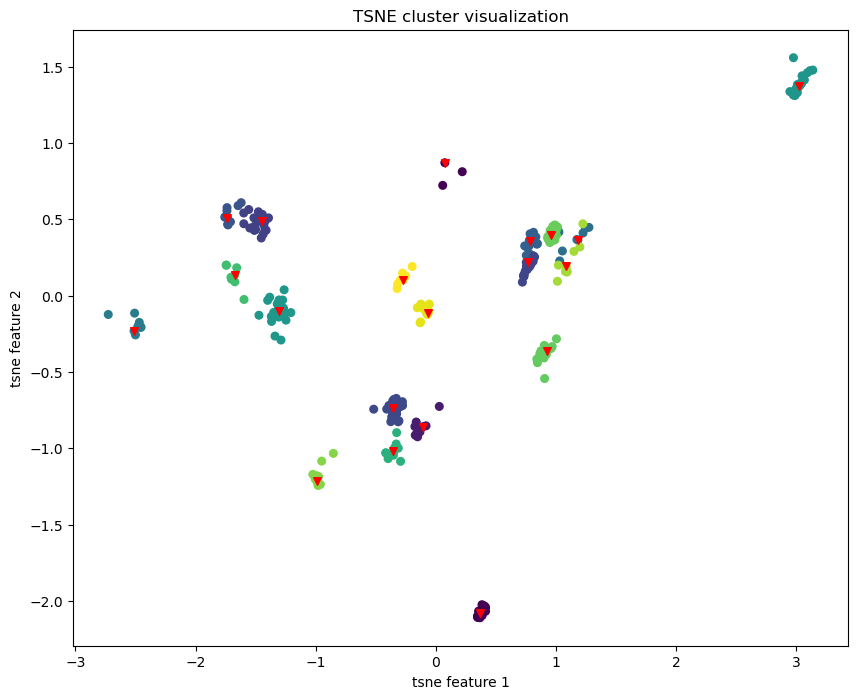

In [61]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import random

randClusters = random.sample(range(0, 999), 20)
print('Clusters sampled: ')
print(randClusters)

subsetDf = centers_df[centers_df['Cluster'].isin(randClusters)]
subsetSoap = subsetDf.drop(columns='Cluster').values

subsetFullDf = df_pca[df_pca['Cluster'].isin(randClusters)]
subsetFullSoap = subsetFullDf.drop(columns='Cluster').values

tsne = TSNE(n_components=2, perplexity=5)
tsneFeatures = tsne.fit_transform(subsetSoap)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(subsetFullSoap[:, 0], subsetFullSoap[:, 1], s=30, c=subsetFullDf['Cluster'], cmap='viridis')
ax.scatter(subsetSoap[:, 0], subsetSoap[:, 1], s=30, c='red', marker='v')

ax.set_xlabel('tsne feature 1')
ax.set_ylabel('tsne feature 2')
ax.set_title('TSNE cluster visualization')